# Flowers Recognition — Machine Learning Project

This project classifies three types of flowers: **daisy, sunflower, and tulip**. It compares two classification algorithms, **Logistic Regression** and **KNN**, with **K-Means clustering**.

The images are cleaned, resized, and converted into numerical features using raw pixels, HOG, and HSV color histograms. The dataset is divided into Training (70%), Validation (15%), and Test (15%) sets, with `random_state=42` for reproducible results.

Model settings are selected using the Validation set. The Test set is used for final evaluation, although the same dataset was also evaluated during earlier project versions.


## 1. Libraries and Project Settings

Import the libraries used for image processing, feature extraction, model training, and evaluation. This section also defines the flower classes and the dataset and output paths.


In [5]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.fft import dctn
from skimage.color import rgb2gray, rgb2hsv
from skimage.feature import hog
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, silhouette_score)
import joblib

RANDOM_STATE = 42
IMAGE_SIZE = (128, 128)
CLASS_NAMES = ["daisy", "sunflower", "tulip"]
DATA_DIR = Path("data/flowers")
OUTPUT_DIR = Path("outputs")
NEW_IMAGES_DIR = Path("new_images")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
MODEL_PATH = OUTPUT_DIR / "flowers_best_model.joblib"
OUTPUT_DIR.mkdir(exist_ok=True)
NEW_IMAGES_DIR.mkdir(exist_ok=True)

print("Ready. Data folder:", DATA_DIR.resolve())

Ready. Data folder: C:\Users\Dell\Downloads\Part_B_Flowers_Recognition\data\flowers


### Image Processing Functions

These functions open an image and extract its features. The same processing is used for training images and new images during prediction.


In [6]:
def open_image(path):
    with Image.open(path) as img:
        return ImageOps.exif_transpose(img).convert("RGB")

In [7]:
def extract_features(path):
    image = open_image(path)
    rgb = np.asarray(image.resize(IMAGE_SIZE, Image.Resampling.BILINEAR), dtype=np.float32) / 255.0
    raw = np.asarray(image.resize((24, 24), Image.Resampling.BILINEAR), dtype=np.float32).ravel() / 255.0
    shape = hog(rgb2gray(rgb), orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))

    hsv = rgb2hsv(rgb)
    height, width = hsv.shape[:2]
    row_mid, col_mid = height // 2, width // 2
    parts = [hsv, hsv[height // 4:3 * height // 4, width // 4:3 * width // 4],
             hsv[:row_mid, :col_mid], hsv[:row_mid, col_mid:],
             hsv[row_mid:, :col_mid], hsv[row_mid:, col_mid:]]
    color = []
    for part in parts:
        hue, sat, value = part.reshape(-1, 3).T
        hs_hist, _, _ = np.histogram2d(hue, sat, bins=(18, 8), range=((0, 1), (0, 1)))
        value_hist, _ = np.histogram(value, bins=12, range=(0, 1))
        color.extend([hs_hist.ravel() / len(hue), value_hist / len(hue)])
    return np.concatenate([raw, shape, *color]).astype(np.float32)

## 2. Load the Dataset

The dataset is organized into folders, with one folder for each flower class. Only **daisy**, **sunflower**, and **tulip** are included in this project.


In [8]:
rows = []
for flower in CLASS_NAMES:
    folder = DATA_DIR / flower
    if not folder.is_dir():
        raise FileNotFoundError(f"Folder missing: {folder.resolve()}")
    for path in sorted(folder.rglob("*")):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            rows.append([str(path), flower])

files = pd.DataFrame(rows, columns=["path", "label"])
if files.empty:
    raise ValueError("No images found inside data/flowers")
print("Original images:", len(files))
print(files["label"].value_counts().sort_index())

Original images: 2481
label
daisy        764
sunflower    733
tulip        984
Name: count, dtype: int64


## 3. Data Cleaning

Before training, the images are checked for unreadable files and duplicates. Identical image content is detected using a SHA-256 hash. A DCT-based fingerprint is also used to keep images with matching fingerprints in the same data split, reducing the risk of similar images appearing in both training and testing.

This fingerprint is a simple grouping method, not a separate model. It does not detect every near-duplicate image, so it cannot guarantee that all visually similar photos have been found.


In [9]:
clean_rows = []
unreadable = []
for path, flower in files.itertuples(index=False, name=None):
    try:
        image = open_image(path)
        if image.width == 0 or image.height == 0:
            raise ValueError("Empty image")
        exact_hash = hashlib.sha256(str(image.size).encode() + image.tobytes()).hexdigest()
        small = image.convert("L").resize((32, 32), Image.Resampling.BILINEAR)
        values = dctn(np.asarray(small, dtype=float))[:8, :8].ravel()[1:]
        median = np.median(values)
        fingerprint = "".join(str(int(value > median)) for value in values)
        clean_rows.append([path, flower, exact_hash, fingerprint])
    except (OSError, ValueError, Image.DecompressionBombError) as error:
        unreadable.append([path, flower, str(error)])

clean = pd.DataFrame(clean_rows, columns=["path", "label", "hash", "group"])
# Remove files with conflicting labels (exact or near-duplicate groups).
conflict = ((clean.groupby("hash")["label"].transform("nunique") > 1) |
            (clean.groupby("group")["label"].transform("nunique") > 1))
removed_conflicts = clean[conflict]
consistent = clean[~conflict]
clean = consistent.drop_duplicates("hash").reset_index(drop=True)
duplicates = len(consistent) - len(clean)

print("Unreadable:", len(unreadable), "Conflicting:", len(removed_conflicts))
print("Exact copies removed:", duplicates, "| Clean images:", len(clean))
print(clean["label"].value_counts().sort_index())
if set(clean["label"]) != set(CLASS_NAMES):
    raise ValueError("Some class has no valid images")

Unreadable: 0 Conflicting: 0
Exact copies removed: 2 | Clean images: 2479
label
daisy        764
sunflower    731
tulip        984
Name: count, dtype: int64


## 4. Image Preprocessing and Feature Extraction

Each image is resized to **128 × 128** for feature extraction, and pixel values are normalized to the range **0–1**. Three types of features are used:

- **Raw pixels:** a smaller 24 × 24 version of the image is flattened into a numerical vector.
- **HOG:** describes edges and shapes in the image.
- **HSV color histograms:** describe color distributions across the image and selected regions.

These features give the models information about both flower shape and color.


In [10]:
X = np.array([extract_features(path) for path in clean["path"]])
print("Extracted feature matrix:", X.shape)
assert np.isfinite(X).all()

Extracted feature matrix: (2479, 4428)


## 5. Label Encoding

The flower names are converted into numerical labels so they can be used by the machine learning models.


In [11]:
encoder = LabelEncoder()
y = encoder.fit_transform(clean["label"])
labels = np.arange(len(encoder.classes_))
print("Class IDs:", dict(enumerate(encoder.classes_)))

Class IDs: {0: 'daisy', 1: 'sunflower', 2: 'tulip'}


## 6. Train, Validation, and Test Split

The data is divided into approximately **70% Training, 15% Validation, and 15% Test**. The split is stratified to keep the flower classes reasonably balanced and uses `random_state=42` for reproducibility.

Images with the same DCT fingerprint stay in one split to help prevent data leakage. Because the split is based on groups rather than individual images, the final percentages may not be exact. The training samples are shuffled while keeping each image matched with its label.


In [12]:
groups = clean.drop_duplicates("group")
train_groups, remaining_groups = train_test_split(
    groups, test_size=0.30, stratify=groups["label"], shuffle=True, random_state=RANDOM_STATE)
val_groups, test_groups = train_test_split(
    remaining_groups, test_size=0.50, stratify=remaining_groups["label"],
    shuffle=True, random_state=RANDOM_STATE)

rng = np.random.default_rng(RANDOM_STATE)
split_indices = {}
clean["split"] = ""
for name, groups in [("Train", train_groups), ("Validation", val_groups), ("Test", test_groups)]:
    rows = clean.index[clean["group"].isin(groups["group"])]
    indices = rng.permutation(rows.to_numpy())
    split_indices[name] = indices
    clean.loc[indices, "split"] = name

train_idx = split_indices["Train"]
val_idx = split_indices["Validation"]
test_idx = split_indices["Test"]
assert len(np.unique(np.concatenate([train_idx, val_idx, test_idx]))) == len(clean)
assert clean.groupby("group")["split"].nunique().max() == 1

X_train, X_val = X[train_idx], X[val_idx]
y_train, y_val = y[train_idx], y[val_idx]

print("First 20 shuffled training labels:", encoder.inverse_transform(y_train[:20]).tolist())
counts = pd.crosstab(clean["label"], clean["split"])[["Train", "Validation", "Test"]]
print(counts)
print("Split sizes:", counts.sum().to_dict())
clean.to_csv(OUTPUT_DIR / "clean_images.csv", index=False)

First 20 shuffled training labels: ['sunflower', 'sunflower', 'sunflower', 'daisy', 'sunflower', 'sunflower', 'tulip', 'daisy', 'daisy', 'sunflower', 'sunflower', 'daisy', 'tulip', 'sunflower', 'daisy', 'tulip', 'daisy', 'sunflower', 'sunflower', 'tulip']
split      Train  Validation  Test
label                             
daisy        535         114   115
sunflower    512         110   109
tulip        690         147   147
Split sizes: {'Train': 1737, 'Validation': 371, 'Test': 371}


## 7. Feature Scaling and PCA

`StandardScaler` and **PCA (40 components)** are fitted using the Training set only. The fitted transformations are then applied to the Validation and Test sets.

Each model uses a different feature representation:

- **Logistic Regression:** HOG and HSV color features after scaling and PCA.
- **KNN:** normalized HSV color histograms.
- **K-Means:** raw pixel features after scaling and PCA.


In [13]:
raw_end = 24 * 24 * 3
hog_end = raw_end + 1764
feature_blocks = {
    "raw": slice(0, raw_end),
    "hog": slice(raw_end, hog_end),
    "color": slice(hog_end, None),
}

scalers, pcas = {}, {}
train_reduced, val_reduced = {}, {}
for name, columns in feature_blocks.items():
    scaler = StandardScaler()
    pca = PCA(n_components=40, svd_solver="randomized", random_state=RANDOM_STATE)
    scaled_train = scaler.fit_transform(X_train[:, columns])
    train_reduced[name] = pca.fit_transform(scaled_train)
    val_reduced[name] = pca.transform(scaler.transform(X_val[:, columns]))
    scalers[name], pcas[name] = scaler, pca

X_train_lr = np.hstack([train_reduced["hog"], train_reduced["color"]])
X_val_lr = np.hstack([val_reduced["hog"], val_reduced["color"]])
X_train_knn, X_val_knn = X_train[:, hog_end:], X_val[:, hog_end:]
X_train_km, X_val_km = train_reduced["raw"], val_reduced["raw"]

## 8. Logistic Regression

Logistic Regression is trained with several values of `C`, which controls regularization. A smaller `C` applies stronger regularization.

The model selection is based on Validation accuracy. When multiple settings are within one percentage point of the highest Validation accuracy, the setting with the smaller Train–Validation accuracy gap is preferred.


In [14]:
lr_rows = []
for c in [0.003, 0.01, 0.03, 0.1]:
    model = LogisticRegression(C=c, max_iter=500, random_state=RANDOM_STATE)
    model.fit(X_train_lr, y_train)
    train_acc = model.score(X_train_lr, y_train)
    val_acc = model.score(X_val_lr, y_val)
    lr_rows.append([c, train_acc, val_acc, abs(train_acc - val_acc)])

lr_table = pd.DataFrame(lr_rows, columns=["C", "Train", "Validation", "Gap"])
print(lr_table.round(4).to_string(index=False))
close_lr = lr_table[lr_table["Validation"] >= lr_table["Validation"].max() - 0.01]
best_lr_row = close_lr.sort_values(["Gap", "Validation"], ascending=[True, False]).iloc[0]
best_lr_c = float(best_lr_row["C"])
logistic_model = LogisticRegression(C=best_lr_c, max_iter=500, random_state=RANDOM_STATE)
logistic_model.fit(X_train_lr, y_train)
print("Selected Logistic Regression C:", best_lr_c)

    C  Train  Validation    Gap
0.003 0.8158      0.7628 0.0530
0.010 0.8152      0.7655 0.0497
0.030 0.8204      0.7682 0.0522
0.100 0.8187      0.7682 0.0505
Selected Logistic Regression C: 0.01


## 9. K-Nearest Neighbors (KNN)

KNN is evaluated using different numbers of neighbors and two distance measures: **Manhattan** and **Euclidean**.

The final setting is selected from the Validation results, using the Train–Validation gap to compare settings with similar accuracy.


In [15]:
knn_rows = []
for metric in ["manhattan", "euclidean"]:
    for k in [9, 15, 25, 41]:
        model = KNeighborsClassifier(n_neighbors=k, metric=metric, weights="uniform")
        model.fit(X_train_knn, y_train)
        train_acc = model.score(X_train_knn, y_train)
        val_acc = model.score(X_val_knn, y_val)
        knn_rows.append([k, metric, train_acc, val_acc, abs(train_acc - val_acc)])

knn_table = pd.DataFrame(knn_rows, columns=["K", "Distance", "Train", "Validation", "Gap"])
print(knn_table.round(4).to_string(index=False))
close_knn = knn_table[knn_table["Validation"] >= knn_table["Validation"].max() - 0.01]
best_knn_row = close_knn.sort_values(["Gap", "Validation"], ascending=[True, False]).iloc[0]
knn_model = KNeighborsClassifier(n_neighbors=int(best_knn_row["K"]),
                                  metric=best_knn_row["Distance"], weights="uniform")
knn_model.fit(X_train_knn, y_train)
print("Selected KNN:", knn_model)

c:\Users\Dell\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Dell\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Dell\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Dell\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File

 K  Distance  Train  Validation    Gap
 9 manhattan 0.8077      0.7412 0.0665
15 manhattan 0.8002      0.7358 0.0644
25 manhattan 0.7772      0.7439 0.0333
41 manhattan 0.7789      0.7305 0.0485
 9 euclidean 0.7473      0.6226 0.1246
15 euclidean 0.7087      0.6199 0.0887
25 euclidean 0.6874      0.6307 0.0567
41 euclidean 0.6638      0.6065 0.0573
Selected KNN: KNeighborsClassifier(metric='manhattan', n_neighbors=25)


## 10. K-Means Clustering

K-Means groups images based on similarities in their features, without using flower labels during clustering.

The experiment compares **3, 6, 12, and 24 clusters**. After clustering, each cluster is assigned the most common flower label among its Training images (**majority voting**). The number of clusters is selected using Validation accuracy after this mapping.

The **Silhouette Score** is reported later to assess how clearly the clusters are separated.


In [16]:
def map_clusters(cluster_ids, true_labels, number_of_clusters):
    majority_labels = []
    for cluster in range(number_of_clusters):
        members = true_labels[cluster_ids == cluster]
        if len(members) == 0:
            members = true_labels
        majority_labels.append(np.bincount(members, minlength=len(labels)).argmax())
    return np.array(majority_labels)

km_rows = []
for clusters in [3, 6, 12, 24]:
    model = KMeans(n_clusters=clusters, n_init=10, random_state=RANDOM_STATE)
    model.fit(X_train_km)  # no y_train here
    mapping = map_clusters(model.labels_, y_train, clusters)
    train_acc = accuracy_score(y_train, mapping[model.predict(X_train_km)])
    val_acc = accuracy_score(y_val, mapping[model.predict(X_val_km)])
    km_rows.append([clusters, train_acc, val_acc])

km_table = pd.DataFrame(km_rows, columns=["Clusters", "Train", "Validation"])
print(km_table.round(4).to_string(index=False))
best_cluster_count = int(km_table.sort_values("Validation", ascending=False).iloc[0]["Clusters"])
kmeans_model = KMeans(n_clusters=best_cluster_count, n_init=10, random_state=RANDOM_STATE)
kmeans_model.fit(X_train_km)
cluster_mapping = map_clusters(kmeans_model.labels_, y_train, best_cluster_count)
print("Selected number of clusters:", best_cluster_count)

 Clusters  Train  Validation
        3 0.4151      0.3801
        6 0.5193      0.5040
       12 0.5452      0.5040
       24 0.5769      0.5903
Selected number of clusters: 24


## 11. Select the Best Classifier

Logistic Regression and KNN are compared using their **Validation accuracy**. K-Means is included in the comparison, but it is evaluated separately because it is an unsupervised method.


In [17]:
development = pd.DataFrame([
    ["Logistic Regression", logistic_model.score(X_train_lr, y_train),
     logistic_model.score(X_val_lr, y_val)],
    ["KNN", knn_model.score(X_train_knn, y_train),
     knn_model.score(X_val_knn, y_val)],
    ["K-Means", accuracy_score(y_train, cluster_mapping[kmeans_model.predict(X_train_km)]),
     accuracy_score(y_val, cluster_mapping[kmeans_model.predict(X_val_km)])],
], columns=["Model", "Train", "Validation"])
development["Gap"] = development["Train"] - development["Validation"]
print(development.round(4).to_string(index=False))

best_name = development.iloc[:2].sort_values("Validation", ascending=False).iloc[0]["Model"]
print("Chosen classifier BEFORE Test evaluation:", best_name)

              Model  Train  Validation     Gap
Logistic Regression 0.8152      0.7655  0.0497
                KNN 0.7772      0.7439  0.0333
            K-Means 0.5769      0.5903 -0.0134
Chosen classifier BEFORE Test evaluation: Logistic Regression


## 12. Final Model Evaluation

The selected models are evaluated on the Test set using the preprocessing fitted on Training data. The evaluation includes **Accuracy, Macro F1, Precision, Recall, F1-score**, and **Confusion Matrices**.

In each confusion matrix, rows represent the actual flower classes and columns represent the predicted classes. The K-Means results also include the **Silhouette Score**.

The Test set was used during earlier versions of this coursework, so these results should be treated as a project benchmark rather than a completely independent external test.


Logistic Regression
              precision  recall  f1-score  support
daisy             0.771   0.730     0.750  115.000
sunflower         0.796   0.789     0.793  109.000
tulip             0.779   0.816     0.797  147.000
accuracy          0.782   0.782     0.782    0.782
macro avg         0.782   0.779     0.780  371.000
weighted avg      0.782   0.782     0.781  371.000


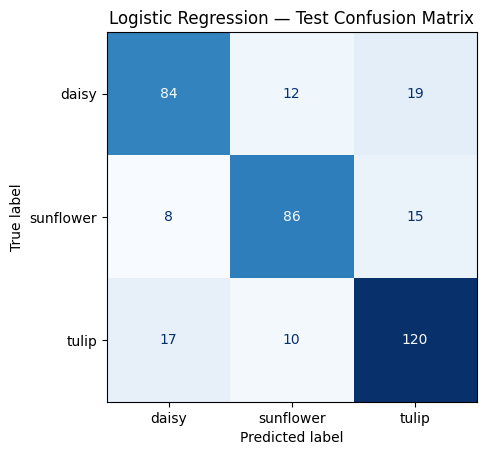

KNN
              precision  recall  f1-score  support
daisy             0.741   0.548     0.630  115.000
sunflower         0.702   0.780     0.739  109.000
tulip             0.703   0.789     0.744  147.000
accuracy          0.712   0.712     0.712    0.712
macro avg         0.716   0.706     0.704  371.000
weighted avg      0.715   0.712     0.707  371.000


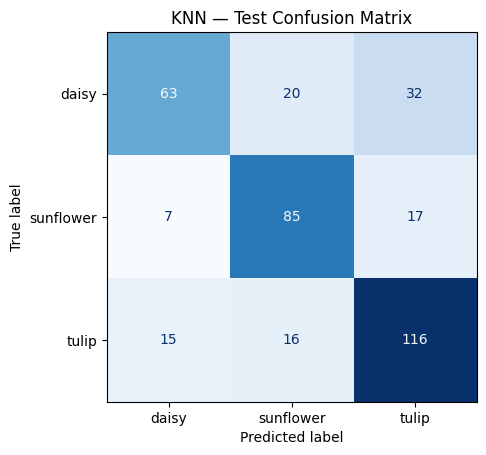

K-Means
              precision  recall  f1-score  support
daisy             0.610   0.652     0.630   115.00
sunflower         0.628   0.450     0.524   109.00
tulip             0.535   0.619     0.574   147.00
accuracy          0.580   0.580     0.580     0.58
macro avg         0.591   0.574     0.576   371.00
weighted avg      0.586   0.580     0.577   371.00


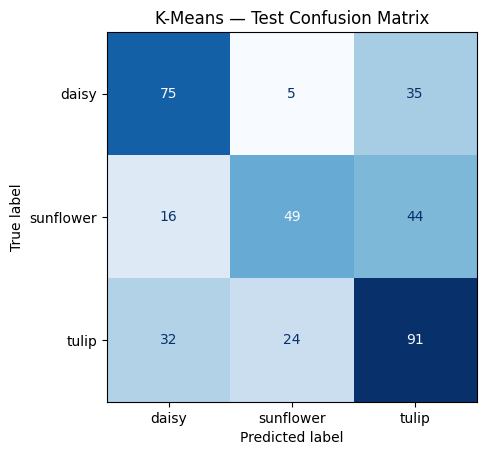

All 9 Confusion Matrices checked successfully.
              Model      Split  Accuracy  Macro F1  Silhouette
Logistic Regression      Train    0.8152    0.8142         NaN
Logistic Regression Validation    0.7655    0.7616         NaN
Logistic Regression       Test    0.7817    0.7800         NaN
                KNN      Train    0.7772    0.7759         NaN
                KNN Validation    0.7439    0.7435         NaN
                KNN       Test    0.7116    0.7042         NaN
            K-Means      Train    0.5769    0.5747      0.0584
            K-Means Validation    0.5903    0.5955      0.0412
            K-Means       Test    0.5795    0.5761      0.0426


In [18]:
X_test, y_test = X[test_idx], y[test_idx]
test_reduced = {}
for name, columns in feature_blocks.items():
    test_reduced[name] = pcas[name].transform(scalers[name].transform(X_test[:, columns]))
X_test_lr = np.hstack([test_reduced["hog"], test_reduced["color"]])
X_test_knn = X_test[:, hog_end:]
X_test_km = test_reduced["raw"]

models = {
    "Logistic Regression": (logistic_model, X_train_lr, X_val_lr, X_test_lr),
    "KNN": (knn_model, X_train_knn, X_val_knn, X_test_knn),
    "K-Means": (kmeans_model, X_train_km, X_val_km, X_test_km)
}
results = []
for name, (model, train_data, val_data, test_data) in models.items():
    filename = name.lower().replace(" ", "_")
    for split, features, truth in [("Train", train_data, y_train),
                                  ("Validation", val_data, y_val),
                                  ("Test", test_data, y_test)]:
        prediction = model.predict(features)
        silhouette = np.nan
        if name == "K-Means":
            if 1 < len(np.unique(prediction)) < len(prediction):
                silhouette = silhouette_score(features, prediction)
            prediction = cluster_mapping[prediction]
        accuracy = accuracy_score(truth, prediction)
        macro_f1 = f1_score(truth, prediction, labels=labels, average="macro", zero_division=0)
        cm = confusion_matrix(truth, prediction, labels=labels)
        assert cm.shape == (len(labels), len(labels))
        assert cm.sum() == len(truth)
        assert np.array_equal(cm.sum(axis=1), np.bincount(truth, minlength=len(labels)))
        assert np.isclose(cm.trace() / cm.sum(), accuracy)
        results.append([name, split, accuracy, macro_f1, silhouette])
        counts = pd.DataFrame(cm, index=encoder.classes_, columns=encoder.classes_)
        counts.to_csv(OUTPUT_DIR / f"{filename}_{split.lower()}_confusion.csv")
        if split == "Test":
            report = classification_report(truth, prediction, labels=labels, target_names=encoder.classes_,
                                           zero_division=0, output_dict=True)
            report = pd.DataFrame(report).T
            report.to_csv(OUTPUT_DIR / f"{filename}_per_class.csv")
            print(name)
            print(report.round(3))
            ConfusionMatrixDisplay(cm, display_labels=encoder.classes_).plot(cmap="Blues", colorbar=False)
            plt.title(name + " — Test Confusion Matrix")
            plt.show()

score_table = pd.DataFrame(results, columns=["Model", "Split", "Accuracy", "Macro F1", "Silhouette"])
score_table.to_csv(OUTPUT_DIR / "results.csv", index=False)
print("All 9 Confusion Matrices checked successfully.")
print(score_table.round(4).to_string(index=False))

## 13. Compare Model Performance

The table and chart compare Training, Validation, and Test accuracy for all three models. The Train–Validation gap helps show how consistently each model performs on unseen validation images.


Split                 Train  Validation    Test  Train–Val Gap  Test Macro F1
Model                                                                        
K-Means              0.5769      0.5903  0.5795        -0.0134         0.5761
KNN                  0.7772      0.7439  0.7116         0.0333         0.7042
Logistic Regression  0.8152      0.7655  0.7817         0.0497         0.7800


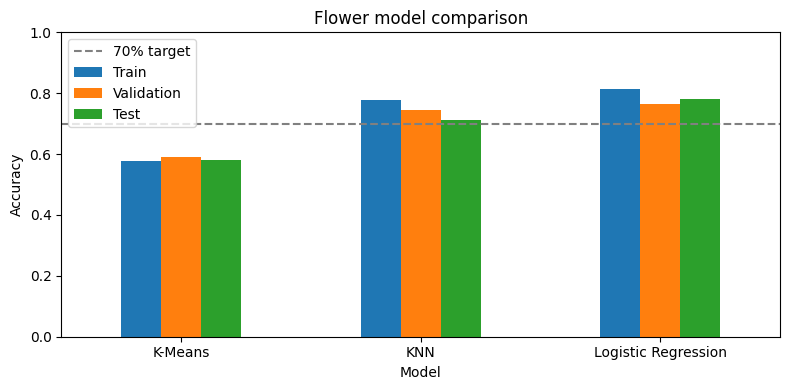

In [19]:
comparison = score_table.pivot(index="Model", columns="Split", values="Accuracy")
comparison = comparison[["Train", "Validation", "Test"]]
comparison["Train–Val Gap"] = comparison["Train"] - comparison["Validation"]
test_scores = score_table[score_table["Split"] == "Test"].set_index("Model")
comparison["Test Macro F1"] = test_scores["Macro F1"]
comparison.to_csv(OUTPUT_DIR / "model_comparison.csv")
print(comparison.round(4).to_string())
comparison[["Train", "Validation", "Test"]].plot.bar(figsize=(8, 4), ylim=(0, 1), rot=0)
plt.axhline(0.70, linestyle="--", color="gray", label="70% target")
plt.ylabel("Accuracy")
plt.title("Flower model comparison")
plt.legend()
plt.tight_layout()
plt.show()

## 14. Save the Model and Predict New Images

The best supervised classifier is saved with its label encoder and the preprocessing objects it needs. This allows new images to be classified without training the model again.

The prediction function uses the same feature extraction process as the training data.


In [20]:
if best_name == "Logistic Regression":
    saved = {"name": best_name, "model": logistic_model, "encoder": encoder,
             "hog_scaler": scalers["hog"], "hog_pca": pcas["hog"],
             "color_scaler": scalers["color"], "color_pca": pcas["color"],
             "raw_end": raw_end, "hog_end": hog_end}
else:
    saved = {"name": best_name, "model": knn_model, "encoder": encoder,
             "hog_end": hog_end}
joblib.dump(saved, MODEL_PATH, compress=3)
print("Saved:", MODEL_PATH)

Saved: outputs\flowers_best_model.joblib


### Predict a New Flower Image

Place the images to classify in the `new_images` folder. The cell below loads the saved model and prints the predicted flower class for each image.


In [21]:
def predict_new_flower(path, loaded):
    features = extract_features(path).reshape(1, -1)
    if loaded["name"] == "Logistic Regression":
        hs = loaded["hog_pca"].transform(loaded["hog_scaler"].transform(
            features[:, loaded["raw_end"]:loaded["hog_end"]]))
        cs = loaded["color_pca"].transform(loaded["color_scaler"].transform(
            features[:, loaded["hog_end"]:]))
        features = np.hstack([hs, cs])
    else:
        features = features[:, loaded["hog_end"]:]
    prediction = loaded["model"].predict(features)
    return loaded["encoder"].inverse_transform(prediction)[0]


loaded = joblib.load(MODEL_PATH)
for path in sorted(NEW_IMAGES_DIR.iterdir()):
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
        print(path.name, "→", predict_new_flower(path, loaded))

In [22]:
# Confirm saved model gives exactly the same result as the in-memory model.
expected = encoder.inverse_transform(models[best_name][0].predict(models[best_name][3][:1]))[0]
assert predict_new_flower(clean.loc[test_idx[0], "path"], loaded) == expected
print("Saved-model prediction check passed.")

Saved-model prediction check passed.


In [23]:

from pathlib import Path
import joblib

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

# 1. Logistic Regression
joblib.dump({
    "model": logistic_model,
    "encoder": encoder,
    "hog_scaler": scalers["hog"],
    "hog_pca": pcas["hog"],
    "color_scaler": scalers["color"],
    "color_pca": pcas["color"],
    "raw_end": raw_end,
    "hog_end": hog_end
}, model_dir / "logistic_regression.joblib")

# 2. KNN
joblib.dump({
    "model": knn_model,
    "encoder": encoder,
    "hog_end": hog_end
}, model_dir / "knn.joblib")

# 3. K-Means
joblib.dump({
    "model": kmeans_model,
    "encoder": encoder,
    "raw_scaler": scalers["raw"],
    "raw_pca": pcas["raw"],
    "cluster_mapping": cluster_mapping,
    "raw_end": raw_end
}, model_dir / "kmeans.joblib")

print("All 3 models saved successfully!")


All 3 models saved successfully!


## 15. Results and Conclusion

The final dataset contains **2,479 images** from three flower classes: **daisy, sunflower, and tulip**. The data split contains **1,737 Training images, 371 Validation images, and 371 Test images**.

| Model | Train Accuracy | Validation Accuracy | Test Accuracy |
|---|---:|---:|---:|
| **Logistic Regression** | **81.52%** | **76.55%** | **78.17%** |
| KNN | 77.72% | 74.39% | 71.16% |
| K-Means | 57.69% | 59.03% | 57.95% |

**Logistic Regression** achieved the highest Validation accuracy among the classifiers and was selected as the final classification model. Its selected regularization setting was **C = 0.01**, and the Train–Validation accuracy gap was approximately **4.97 percentage points**.

**KNN** also performed above 70% on all three splits, although its Test accuracy was lower than Logistic Regression.

**K-Means** performed less accurately after mapping clusters to flower labels. The selected model used **24 clusters**, and its Training Silhouette Score was **0.0584**, indicating that the clusters were not clearly separated. This is expected to be more challenging than supervised classification because K-Means does not use class labels to form clusters.

Overall, **Logistic Regression gave the strongest classification results for the selected three flower types**. The project also shows how feature extraction and the choice between supervised and unsupervised learning affect performance.
